In [7]:
import pandas as pd

df = pd.read_csv("CAR DETAILS FROM CAR DEKHO.csv")

print(df.shape)
print(df.head())
print(df.info())
print(df.describe(include='all'))
print(df.isnull().sum())
print(df.duplicated().sum())

print("Before:", df.shape)
df.drop_duplicates(inplace=True)
print("After:",df.shape)
print("Duplicates:",df.duplicated().sum())

(4340, 8)
                       name  year  selling_price  km_driven    fuel  \
0             Maruti 800 AC  2007          60000      70000  Petrol   
1  Maruti Wagon R LXI Minor  2007         135000      50000  Petrol   
2      Hyundai Verna 1.6 SX  2012         600000     100000  Diesel   
3    Datsun RediGO T Option  2017         250000      46000  Petrol   
4     Honda Amaze VX i-DTEC  2014         450000     141000  Diesel   

  seller_type transmission         owner  
0  Individual       Manual   First Owner  
1  Individual       Manual   First Owner  
2  Individual       Manual   First Owner  
3  Individual       Manual   First Owner  
4  Individual       Manual  Second Owner  
<class 'pandas.DataFrame'>
RangeIndex: 4340 entries, 0 to 4339
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   name           4340 non-null   str  
 1   year           4340 non-null   int64
 2   selling_price  4340 non-null   int64


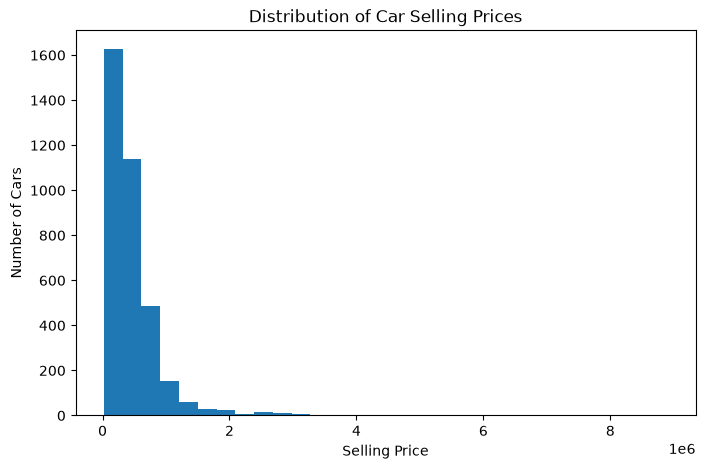

In [8]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
plt.hist(df["selling_price"],bins=30)
plt.xlabel("Selling Price")
plt.ylabel("Number of Cars")
plt.title("Distribution of Car Selling Prices")
plt.show()

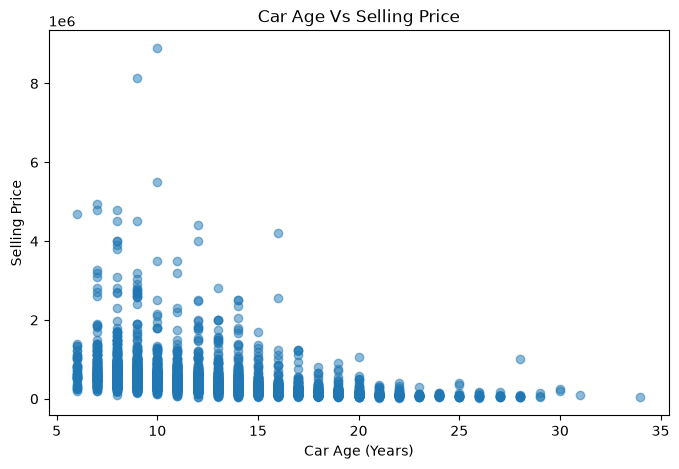

In [9]:
current_year = 2026
df["car_age"] = current_year - df["year"]

plt.figure(figsize=(8,5))
plt.scatter(df["car_age"],df["selling_price"],alpha=0.5)
plt.xlabel("Car Age (Years)")
plt.ylabel("Selling Price")
plt.title("Car Age Vs Selling Price")
plt.show()

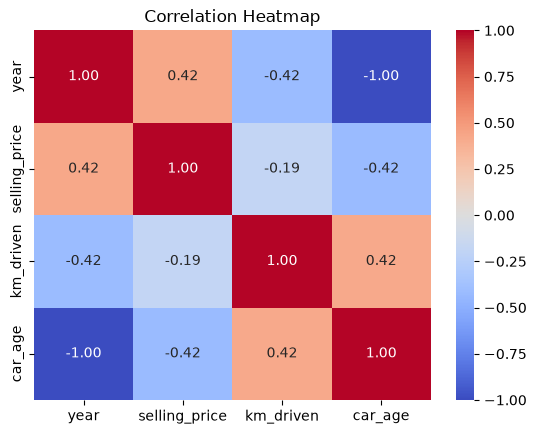

In [46]:
import seaborn as sns

numeric_df = df.select_dtypes(include="number")
plt.Figure(figsize=(9,6))
sns.heatmap(numeric_df.corr(),annot=True,cmap="coolwarm",fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

In [47]:
print(df.dtypes)

for col in df.select_dtypes(include="object").columns:
    print(f"\n{col}:")
    print(df[col].value_counts())

name               str
year             int64
selling_price    int64
km_driven        int64
fuel               str
seller_type        str
transmission       str
owner              str
car_age          int64
dtype: object

name:
name
Maruti Swift Dzire VDI                          54
Maruti Alto 800 LXI                             48
Maruti Alto LXi                                 42
Maruti Alto LX                                  30
Hyundai EON Era Plus                            28
                                                ..
Maruti Swift LDI                                 1
Tata Nano XM                                     1
Mahindra Verito 1.5 D6 BSIII                     1
Toyota Innova 2.5 VX (Diesel) 8 Seater BS IV     1
Hyundai i20 Magna 1.4 CRDi                       1
Name: count, Length: 1491, dtype: int64

fuel:
fuel
Diesel      1800
Petrol      1717
CNG           37
LPG           22
Electric       1
Name: count, dtype: int64

seller_type:
seller_type
Individual       

C:\Users\Admin\AppData\Local\Temp\ipykernel_14024\1901421069.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include="object").columns:


In [48]:
X = df.drop(columns=["selling_price","year","name"])
y = df["selling_price"]

X = pd.get_dummies(X, drop_first=True,dtype=int)
print(X.head())
print("Features shape:", X.shape)
print("Target shape:", y.shape)

   km_driven  car_age  fuel_Diesel  fuel_Electric  fuel_LPG  fuel_Petrol  \
0      70000       19            0              0         0            1   
1      50000       19            0              0         0            1   
2     100000       14            1              0         0            0   
3      46000        9            0              0         0            1   
4     141000       12            1              0         0            0   

   seller_type_Individual  seller_type_Trustmark Dealer  transmission_Manual  \
0                       1                             0                    1   
1                       1                             0                    1   
2                       1                             0                    1   
3                       1                             0                    1   
4                       1                             0                    1   

   owner_Fourth & Above Owner  owner_Second Owner  owner_Test 

In [49]:
from sklearn.model_selection import train_test_split 

X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.2, random_state=42)

print("X_train:",X_train.shape)
print("X_test:",X_test.shape)
print("y_train:",y_train.shape)
print("y_test:",y_test.shape)

X_train: (2861, 13)
X_test: (716, 13)
y_train: (2861,)
y_test: (716,)


In [50]:
from sklearn.linear_model import LinearRegression

lr_model = LinearRegression()

lr_model.fit(X_train,y_train)

print("Linear Regression Model Trained Successfully!")

y_pred = lr_model.predict(X_test)

print("Actual Prices:")
print(y_test.head(10).values)

print("\nPredicted Prices:")
print(y_pred[:10])

Linear Regression Model Trained Successfully!
Actual Prices:
[ 270000  525000  990000 3800000  229999  325000  210000  500000  790000
  360000]

Predicted Prices:
[ 488618.55876767  478334.28113052  628427.3407996  1569713.65424204
   33909.8060065   347305.45899453  127300.40492694  668712.8104434
  783671.40301554  297296.92413968]


In [51]:
from sklearn.metrics import r2_score,mean_absolute_error,mean_squared_error
import numpy as np

r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test,y_pred)
rmse = np.sqrt(mean_squared_error(y_test,y_pred))

print("R2 Score:", round(r2,3))
print("MAE:", round(mae, 2))
print("RMSE:",round(rmse,2))

R2 Score: 0.393
MAE: 213071.18
RMSE: 442304.97


In [52]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import r2_score,mean_absolute_error,mean_squared_error
import numpy as np

dt_model = DecisionTreeRegressor(
    max_depth=10,
    min_samples_leaf=5,
    random_state=42
)

dt_model.fit(X_train, y_train)
dt_pred = dt_model.predict(X_test)

print("Dicision Tree R2:",round(r2_score(y_test,dt_pred),3))
print("Dicision Tree MAE:",round(mean_absolute_error(y_test,dt_pred),2))
print("Dicision Tree RMSE:",round(np.sqrt(mean_squared_error(y_test,dt_pred)),2))

Dicision Tree R2: 0.404
Dicision Tree MAE: 194645.31
Dicision Tree RMSE: 438079.76


In [58]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=15,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train,y_train)
rf_pred = rf_model.predict(X_test)

print("Random Forest R2:",round(r2_score(y_test,rf_pred),3))
print("Random Forest MAE:",round(mean_absolute_error(y_test,rf_pred),2))
print("Random Forest RMSE:",round(np.sqrt(mean_squared_error(y_test,rf_pred)),2))

Random Forest R2: 0.469
Random Forest MAE: 184221.51
Random Forest RMSE: 413504.55


In [59]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import RandomizedSearchCV

param_grid = {
    "n_estimators":[100,200,300,400],
    "max_depth":[None,10,15,20,25,30],
    "min_samples_split":[2,5,10,15],
    "min_samples_leaf":[1,2,4,6],
    "max_features": [1.0,"sqrt",0.8]
}

rf = RandomForestRegressor(random_state=42,n_jobs=-1)

search = RandomizedSearchCV(
    estimator=rf,
    param_distributions=param_grid,
    n_iter=25,
    cv=5,
    scoring="r2",
    random_state=42,
    n_jobs=-1,
    verbose=1
)

search.fit(X_train,y_train)

best_rf = search.best_estimator_
tuned_pred = best_rf.predict(X_test)

print("Best Parameters:",search.best_params_)
print("Best CV R2:",round(search.best_score_,3))
print("Test R2:",round(r2_score(y_test,tuned_pred),3))
print("Test MAE:",round(mean_absolute_error(y_test,tuned_pred),2))
print("Test RMSE:",round(np.sqrt(mean_squared_error(y_test,tuned_pred)),2))


Fitting 5 folds for each of 25 candidates, totalling 125 fits
Best Parameters: {'n_estimators': 200, 'min_samples_split': 10, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': 10}
Best CV R2: 0.519
Test R2: 0.494
Test MAE: 177302.23
Test RMSE: 403659.85


In [60]:
df_brand = df.copy()

df_brand["brand"] = df_brand["name"].str.split().str[0].str.lower()

X_brand = df_brand.drop(
    columns=["selling_price", "year", "name"]
)

X_brand = pd.get_dummies(X_brand, drop_first=True, dtype=int)

Xb_train = X_brand.loc[X_train.index]
Xb_test = X_brand.loc[X_test.index]

brand_model = RandomForestRegressor(
    **search.best_params_,
    random_state=42,
    n_jobs=-1
)

brand_model.fit(Xb_train, y_train)
brand_pred = brand_model.predict(Xb_test)

print("Brand Model R2:", round(r2_score(y_test, brand_pred), 3))
print("Brand Model MAE:", round(mean_absolute_error(y_test, brand_pred), 2))
print("Brand Model RMSE:", round(np.sqrt(mean_squared_error(y_test, brand_pred)), 2))

Brand Model R2: 0.555
Brand Model MAE: 159182.56
Brand Model RMSE: 378447.84


                          R2         MAE        RMSE
Linear Regression      0.393  213071.177  442304.969
Decision Tree          0.404  194645.307  438079.763
Tuned Random Forest    0.494  177302.228  403659.849
Random Forest + Brand  0.555  159182.563  378447.844


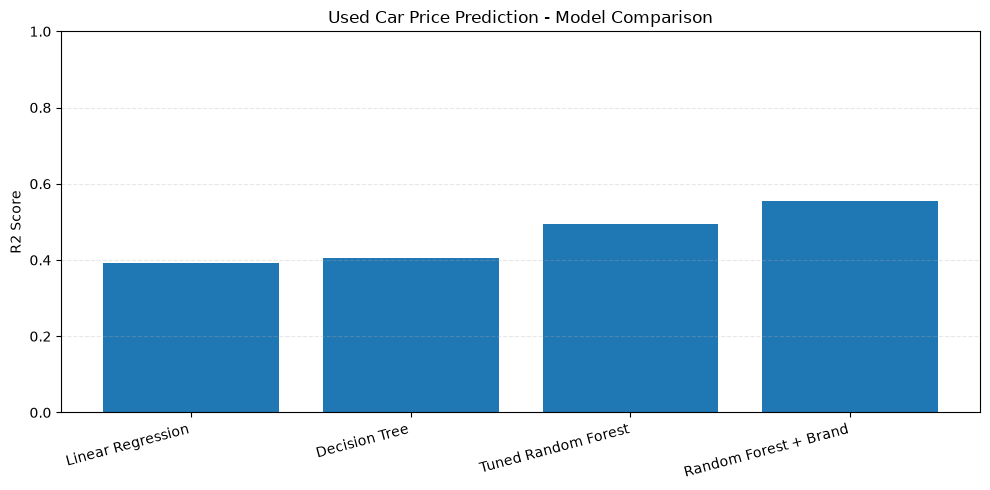

In [61]:
results = {
    "Linear Regression": {
        "R2": r2_score(y_test, y_pred),
        "MAE": mean_absolute_error(y_test, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred))
    },
    "Decision Tree": {
        "R2": r2_score(y_test, dt_pred),
        "MAE": mean_absolute_error(y_test, dt_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, dt_pred))
    },
    "Tuned Random Forest": {
        "R2": r2_score(y_test, tuned_pred),
        "MAE": mean_absolute_error(y_test, tuned_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, tuned_pred))
    },
    "Random Forest + Brand": {
        "R2": r2_score(y_test, brand_pred),
        "MAE": mean_absolute_error(y_test, brand_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, brand_pred))
    }
}

results_df = pd.DataFrame(results).T
print(results_df.round(3))

plt.figure(figsize=(10, 5))
plt.bar(results_df.index, results_df["R2"])
plt.ylabel("R2 Score")
plt.title("Used Car Price Prediction - Model Comparison")
plt.ylim(0, 1)
plt.xticks(rotation=15, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

In [62]:
import joblib

joblib.dump(brand_model,"car_price_model.pkl")
print("Model saved successfully!")

Model saved successfully!
